In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
DF: pd.DataFrame = pd.read_csv("/beegfs/ws/0/clehm-inferential_statistics_ml/simpsons/experiments/19_simpsons_opt_tl_vgg16_split_AdamW/omniopt/projects/19_simpsons_opt_tl_vgg16_split_AdamW_SEED_1/logs/2023-07-01_14-11-36/nvidia-taurusi8014/gpu_usage.csv", sep=", ")
DF["utilization.gpu [%]"] = DF["utilization.gpu [%]"].apply(lambda x: x.split()[0]).astype(float)
DF["utilization.memory [%]"] = DF["utilization.memory [%]"].apply(lambda x: x.split()[0]).astype(float)
DF["timestamp"] = pd.to_datetime(DF["timestamp"])
DF.set_index(["timestamp", "pci.bus_id"], inplace=True)
DF

/tmp/ipykernel_138800/3841729390.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  DF: pd.DataFrame = pd.read_csv("/beegfs/ws/0/clehm-inferential_statistics_ml/simpsons/experiments/19_simpsons_opt_tl_vgg16_split_AdamW/omniopt/projects/19_simpsons_opt_tl_vgg16_split_AdamW_SEED_1/logs/2023-07-01_14-11-36/nvidia-taurusi8014/gpu_usage.csv", sep=", ")


,,name,driver_version,pstate,pcie.link.gen.max,pcie.link.gen.current,temperature.gpu,utilization.gpu [%],utilization.memory [%],memory.total [MiB],memory.free [MiB],memory.used [MiB]
timestamp,pci.bus_id,,,,,,,,,,,
2023-07-01 14:13:33.045,00000000:0B:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,45,1.0,0.0,40536 MiB,39130 MiB,1406 MiB
2023-07-01 14:13:33.049,00000000:11:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,46,1.0,0.0,40536 MiB,39098 MiB,1438 MiB
2023-07-01 14:13:33.051,00000000:3B:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,46,1.0,0.0,40536 MiB,39102 MiB,1434 MiB
2023-07-01 14:13:33.054,00000000:40:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,45,1.0,0.0,40536 MiB,39336 MiB,1200 MiB
2023-07-01 14:13:33.058,00000000:8B:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,44,1.0,0.0,40536 MiB,39532 MiB,1004 MiB
...,...,...,...,...,...,...,...,...,...,...,...,...
2023-07-02 12:10:02.732,00000000:40:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,44,0.0,0.0,40536 MiB,33752 MiB,6784 MiB
2023-07-02 12:10:02.739,00000000:8B:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,43,0.0,0.0,40536 MiB,33752 MiB,6784 MiB
2023-07-02 12:10:02.745,00000000:90:00.0,NVIDIA A100-SXM4-40GB,470.57.02,P0,4,4,45,0.0,0.0,40536 MiB,33758 MiB,6778 MiB


In [3]:
DF.groupby("pci.bus_id").mean()

,pcie.link.gen.max,pcie.link.gen.current,temperature.gpu,utilization.gpu [%],utilization.memory [%]
pci.bus_id,,,,,
00000000:0B:00.0,4.0,4.0,44.648229,0.305412,0.191007
00000000:11:00.0,4.0,4.0,45.850776,0.374254,0.221647
00000000:3B:00.0,4.0,4.0,45.571628,0.309391,0.194787
00000000:40:00.0,4.0,4.0,44.501194,0.306208,0.195782
00000000:8B:00.0,4.0,4.0,43.653999,0.306009,0.193593
00000000:90:00.0,4.0,4.0,44.875448,0.315758,0.198368
00000000:BB:00.0,4.0,4.0,45.004178,0.307203,0.189415
00000000:C1:00.0,4.0,4.0,42.948070,0.300438,0.182849


In [4]:
DF_agg = DF.reset_index(level="pci.bus_id").groupby("pci.bus_id").resample("5min").mean().reset_index()
DF_agg


,pci.bus_id,timestamp,pcie.link.gen.max,pcie.link.gen.current,temperature.gpu,utilization.gpu [%],utilization.memory [%]
0,00000000:0B:00.0,2023-07-01 14:10:00,4.0,4.0,67.375000,71.625,44.250000
1,00000000:0B:00.0,2023-07-01 14:15:00,4.0,4.0,61.269231,37.000,23.307692
2,00000000:0B:00.0,2023-07-01 14:20:00,4.0,4.0,45.333333,0.000,0.000000
3,00000000:0B:00.0,2023-07-01 14:25:00,4.0,4.0,45.000000,0.000,0.000000
4,00000000:0B:00.0,2023-07-01 14:30:00,4.0,4.0,45.000000,0.000,0.000000
...,...,...,...,...,...,...,...
2115,00000000:C1:00.0,2023-07-02 11:50:00,4.0,4.0,43.000000,0.000,0.000000
2116,00000000:C1:00.0,2023-07-02 11:55:00,4.0,4.0,43.000000,0.000,0.000000
2117,00000000:C1:00.0,2023-07-02 12:00:00,4.0,4.0,43.000000,0.000,0.000000
2118,00000000:C1:00.0,2023-07-02 12:05:00,4.0,4.0,43.000000,0.000,0.000000


/tmp/ipykernel_138800/4093511289.py:2: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(labels=DF_agg["timestamp"].dt.strftime("%Y-%m-%dT%H:%M").unique(), rotation=90)


<Axes: title={'center': 'GPU utilization, avg over 5-minutes'}, xlabel='timestamp', ylabel='utilization.gpu [%]'>

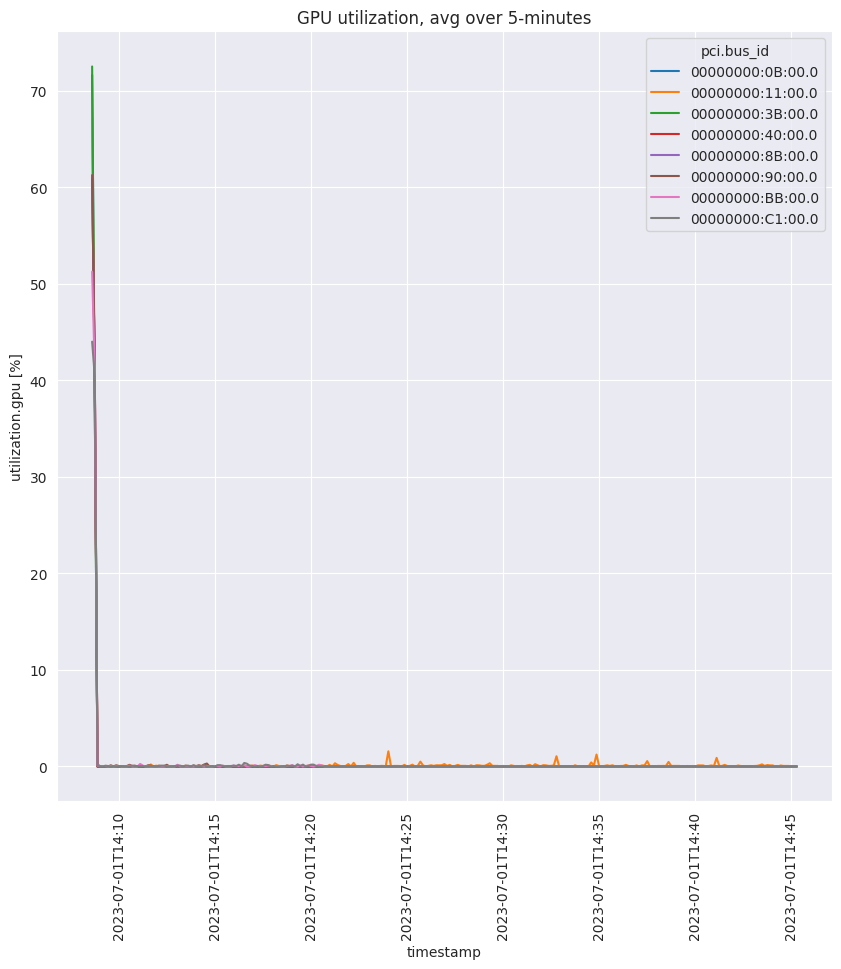

In [5]:
fig, ax = plt.subplots(figsize=(10,10))
_ = ax.set_xticklabels(labels=DF_agg["timestamp"].dt.strftime("%Y-%m-%dT%H:%M").unique(), rotation=90)
ax.set_title("GPU utilization, avg over 5-minutes")
sns.lineplot(
    DF_agg,
    x="timestamp",
    y="utilization.gpu [%]",
    hue="pci.bus_id",
    ax=ax,
)

/tmp/ipykernel_138800/961135707.py:2: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(labels=DF_agg["timestamp"].dt.strftime("%Y-%m-%dT%H:%M").unique(), rotation=90)


<Axes: title={'center': 'GPU memory utilization, avg over 5-minutes'}, xlabel='timestamp', ylabel='utilization.memory [%]'>

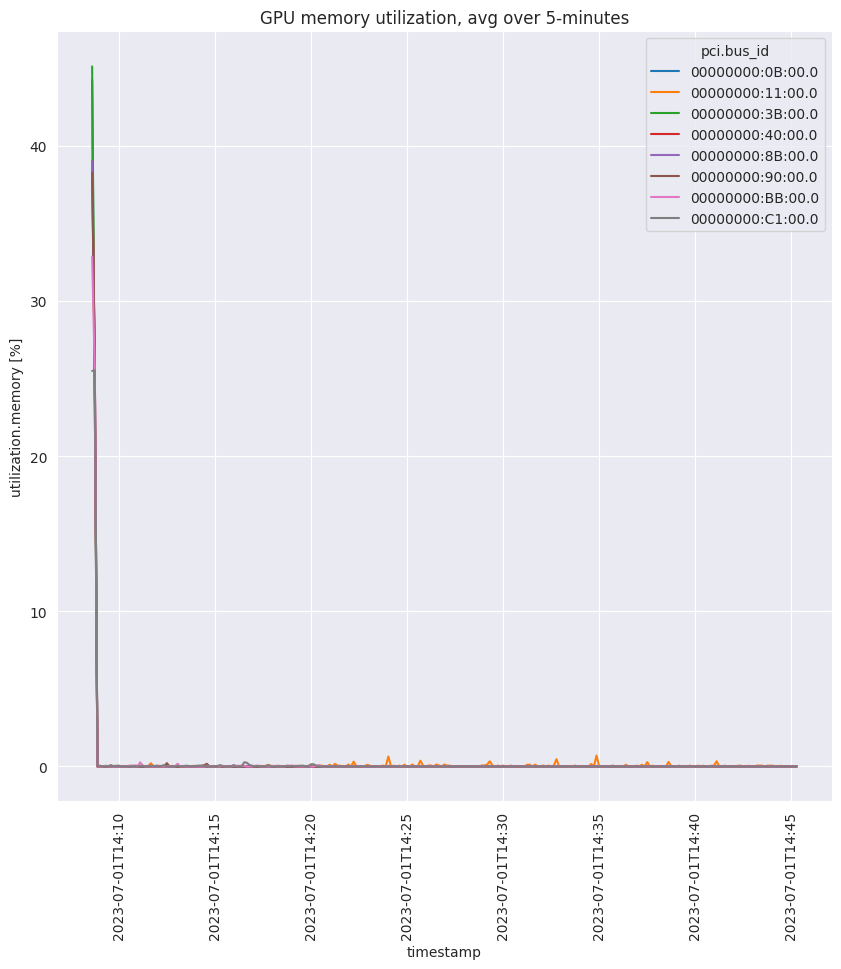

In [6]:
fig, ax = plt.subplots(figsize=(10,10))
_ = ax.set_xticklabels(labels=DF_agg["timestamp"].dt.strftime("%Y-%m-%dT%H:%M").unique(), rotation=90)
ax.set_title("GPU memory utilization, avg over 5-minutes")
sns.lineplot(
    DF_agg,
    x="timestamp",
    y="utilization.memory [%]",
    hue="pci.bus_id",
    ax=ax,
)